# E-Commerce Customer Purchase Prediction Using Logistic Regression
**Company:** ShopSmart | **Domain:** E-Commerce | **Learning type:** Supervised | **Task:** Binary classification (0 = No Purchase, 1 = Purchase)

**Objectives (from project brief)**
1. Understand the dataset and perform EDA
2. Preprocess: missing values, outliers, categorical encoding, feature scaling
3. Build a Logistic Regression model
4. Evaluate (Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC) and predict for new customers

## 1. Import libraries & load data
In Colab, run the cell and upload `Ecommerce_Purchase_Prediction_DataSet.csv` when prompted.

In [49]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve, RocCurveDisplay, classification_report)
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200)

FILE = "Ecommerce_Purchase_Prediction_DataSet.csv"
try:
    from google.colab import files
    import os
    if not os.path.exists(FILE): files.upload()
except ImportError:
    pass
df_raw = pd.read_csv(FILE)
df = df_raw.copy()
df.head()

,Customer_ID,Age,Gender,Device_Type,Traffic_Source,Membership_Type,Payment_Method,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year,Purchase
0,CUST00001,37.0,Female,Mobile,Referral,Regular,Credit Card,6.78,5.0,8,0,4933.27,14.05,2,3.09,0.273,4.07,1,1
1,CUST00002,24.0,Male,Mobile,Organic,Premium,Debit Card,12.79,9.0,5,1,3042.60,7.28,2,48.27,0.045,4.19,0,1
2,CUST00003,42.0,Female,Mobile,Referral,Regular,Wallet,11.72,9.0,5,1,NaN,9.77,4,3.82,0.796,3.37,2,0
3,CUST00004,43.0,Male,Tablet,Referral,Premium,UPI,10.67,7.0,6,3,2776.48,6.78,0,9.24,0.426,5.00,1,1
4,CUST00005,18.0,Male,Desktop,Social Media,Regular,Debit Card,12.06,4.0,3,4,3683.66,16.37,4,4.46,0.347,2.16,0,1


## 2. Understand the data

In [50]:
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate customer IDs:", df["Customer_ID"].duplicated().sum())
df.info()

Shape: (10000, 19)
Duplicate rows: 0 | Duplicate customer IDs: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  object 
 1   Age                    9762 non-null   float64
 2   Gender                 9796 non-null   object 
 3   Device_Type            9855 non-null   object 
 4   Traffic_Source         9760 non-null   object 
 5   Membership_Type        9791 non-null   object 
 6   Payment_Method         9787 non-null   object 
 7   Session_Duration_Min   9776 non-null   float64
 8   Pages_Viewed           10000 non-null  float64
 9   Products_Viewed        10000 non-null  int64  
 10  Cart_Items             10000 non-null  int64  
 11  Cart_Value_INR         9675 non-null   float64
 12  Discount_Percent       9789 non-null   float64
 13  Previous_Orders        10000 non-null  int

In [51]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,9762.0,34.127228,9.546429,18.00,27.000,34.000,40.00000,74.000000
Session_Duration_Min,9776.0,13.117865,12.737399,1.00,6.780,10.835,16.64250,227.756046
Pages_Viewed,10000.0,7.274137,6.055331,1.00,5.000,7.000,9.00000,148.075292
Products_Viewed,10000.0,3.991100,1.999555,0.00,3.000,4.000,5.00000,12.000000
Cart_Items,10000.0,1.523000,1.228015,0.00,1.000,1.000,2.00000,7.000000
Cart_Value_INR,9675.0,1912.614298,3831.569883,14.93,819.930,1433.270,2279.96500,88342.757367
Discount_Percent,9789.0,12.178725,8.143978,0.14,6.450,10.820,16.22000,99.149690
Previous_Orders,10000.0,2.997800,1.725947,0.00,2.000,3.000,4.00000,15.000000
Days_Since_Last_Visit,9820.0,13.314532,26.690252,0.00,3.460,8.470,16.74500,671.772129
Email_Open_Rate,10000.0,0.500227,0.290871,0.00,0.246,0.502,0.75125,1.000000


**Data dictionary (from the brief + columns found)**

| Group | Columns |
|---|---|
| Identifier | `Customer_ID` (not predictive, dropped) |
| Demographics | `Age`, `Gender` |
| Channel / customer type | `Device_Type`, `Traffic_Source`, `Membership_Type`, `Payment_Method` |
| Browsing behaviour | `Session_Duration_Min`, `Pages_Viewed`, `Products_Viewed`, `Days_Since_Last_Visit`, `Email_Open_Rate` |
| Shopping / history | `Cart_Items`, `Cart_Value_INR`, `Discount_Percent`, `Previous_Orders`, `Customer_Rating`, `Returns_Last_Year` |
| **Target** | `Purchase` (0 / 1) |

## 3. Data cleaning: missing values & data-quality audit

,missing,pct
Customer_Rating,325,3.25
Cart_Value_INR,325,3.25
Traffic_Source,240,2.40
Age,238,2.38
Session_Duration_Min,224,2.24
Payment_Method,213,2.13
Discount_Percent,211,2.11
Membership_Type,209,2.09
Gender,204,2.04
Days_Since_Last_Visit,180,1.80


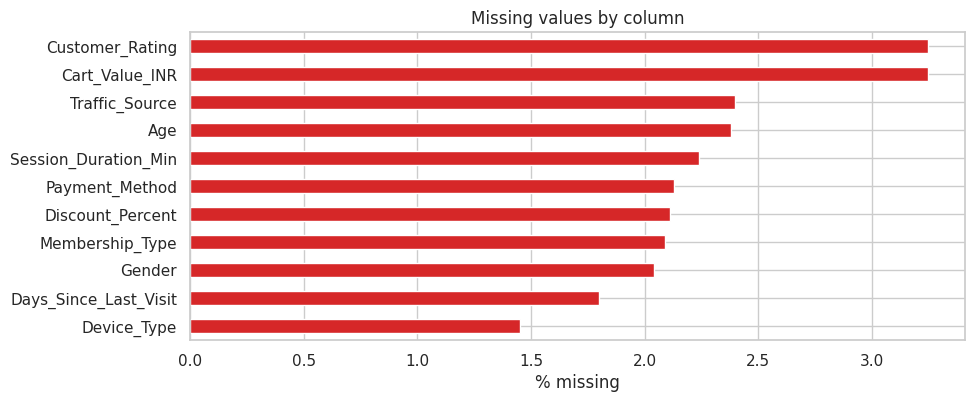

Rows with at least one missing value: 2222 (22.2%)
Missing values in target: 0


In [52]:
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean()*100).round(2)})
display(miss[miss.missing > 0].sort_values("missing", ascending=False))
plt.figure(figsize=(10, 4)); miss[miss.missing > 0]["pct"].sort_values().plot.barh(color="tab:red")
plt.xlabel("% missing"); plt.title("Missing values by column"); plt.show()
print("Rows with at least one missing value:", df.isna().any(axis=1).sum(), f"({df.isna().any(axis=1).mean():.1%})")
print("Missing values in target:", df["Purchase"].isna().sum())

**Treatment decision**
- Missing values are scattered (2-3% per column, none in the target), so dropping rows would discard ~**one third** of the data. We **impute** instead.
- **Numeric -> median** (robust to the extreme outliers present). **Categorical -> mode** (most frequent category).
- Imputation is fitted on the **training set only** inside the final pipeline (Section 8) to prevent data leakage. Below we also apply it to the whole dataset purely to demonstrate the before/after effect for EDA.

In [53]:
df = df_raw.drop(columns="Customer_ID").copy()
TARGET = "Purchase"
num_cols = df.select_dtypes("number").columns.drop(TARGET).tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
cap_cols = ["Age", "Session_Duration_Min", "Pages_Viewed", "Cart_Value_INR", "Discount_Percent", "Days_Since_Last_Visit"]  # continuous
count_cols = [c for c in num_cols if c not in cap_cols]   # discrete counts / bounded scores: valid values, not capped
print("Numeric:", num_cols); print("Categorical:", cat_cols)
print("Capped (continuous):", cap_cols); print("Not capped (counts / bounded):", count_cols)

Numeric: ['Age', 'Session_Duration_Min', 'Pages_Viewed', 'Products_Viewed', 'Cart_Items', 'Cart_Value_INR', 'Discount_Percent', 'Previous_Orders', 'Days_Since_Last_Visit', 'Email_Open_Rate', 'Customer_Rating', 'Returns_Last_Year']
Categorical: ['Gender', 'Device_Type', 'Traffic_Source', 'Membership_Type', 'Payment_Method']
Capped (continuous): ['Age', 'Session_Duration_Min', 'Pages_Viewed', 'Cart_Value_INR', 'Discount_Percent', 'Days_Since_Last_Visit']
Not capped (counts / bounded): ['Products_Viewed', 'Cart_Items', 'Previous_Orders', 'Email_Open_Rate', 'Customer_Rating', 'Returns_Last_Year']


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target distribution

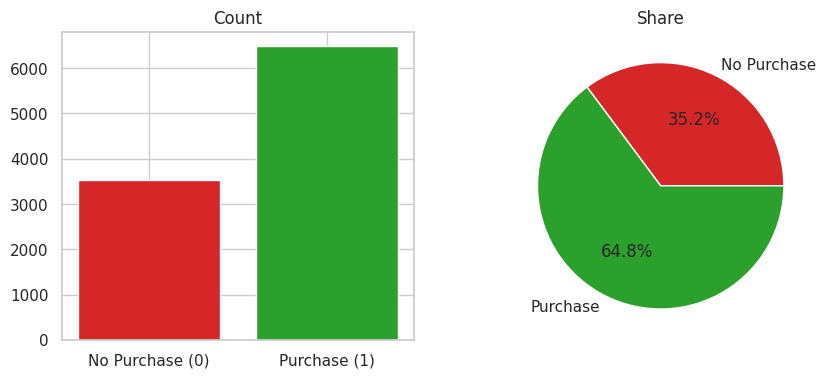

Purchase
0    3520
1    6480
Name: count, dtype: int64 
Overall conversion rate: 0.648


In [54]:
vc = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(["No Purchase (0)", "Purchase (1)"], vc.values, color=["tab:red", "tab:green"]); ax[0].set_title("Count")
ax[1].pie(vc.values, labels=["No Purchase", "Purchase"], autopct="%1.1f%%", colors=["tab:red", "tab:green"]); ax[1].set_title("Share")
plt.show(); print(vc, "\nOverall conversion rate:", round(df[TARGET].mean(), 4))

### 4.2 Numeric features: distributions

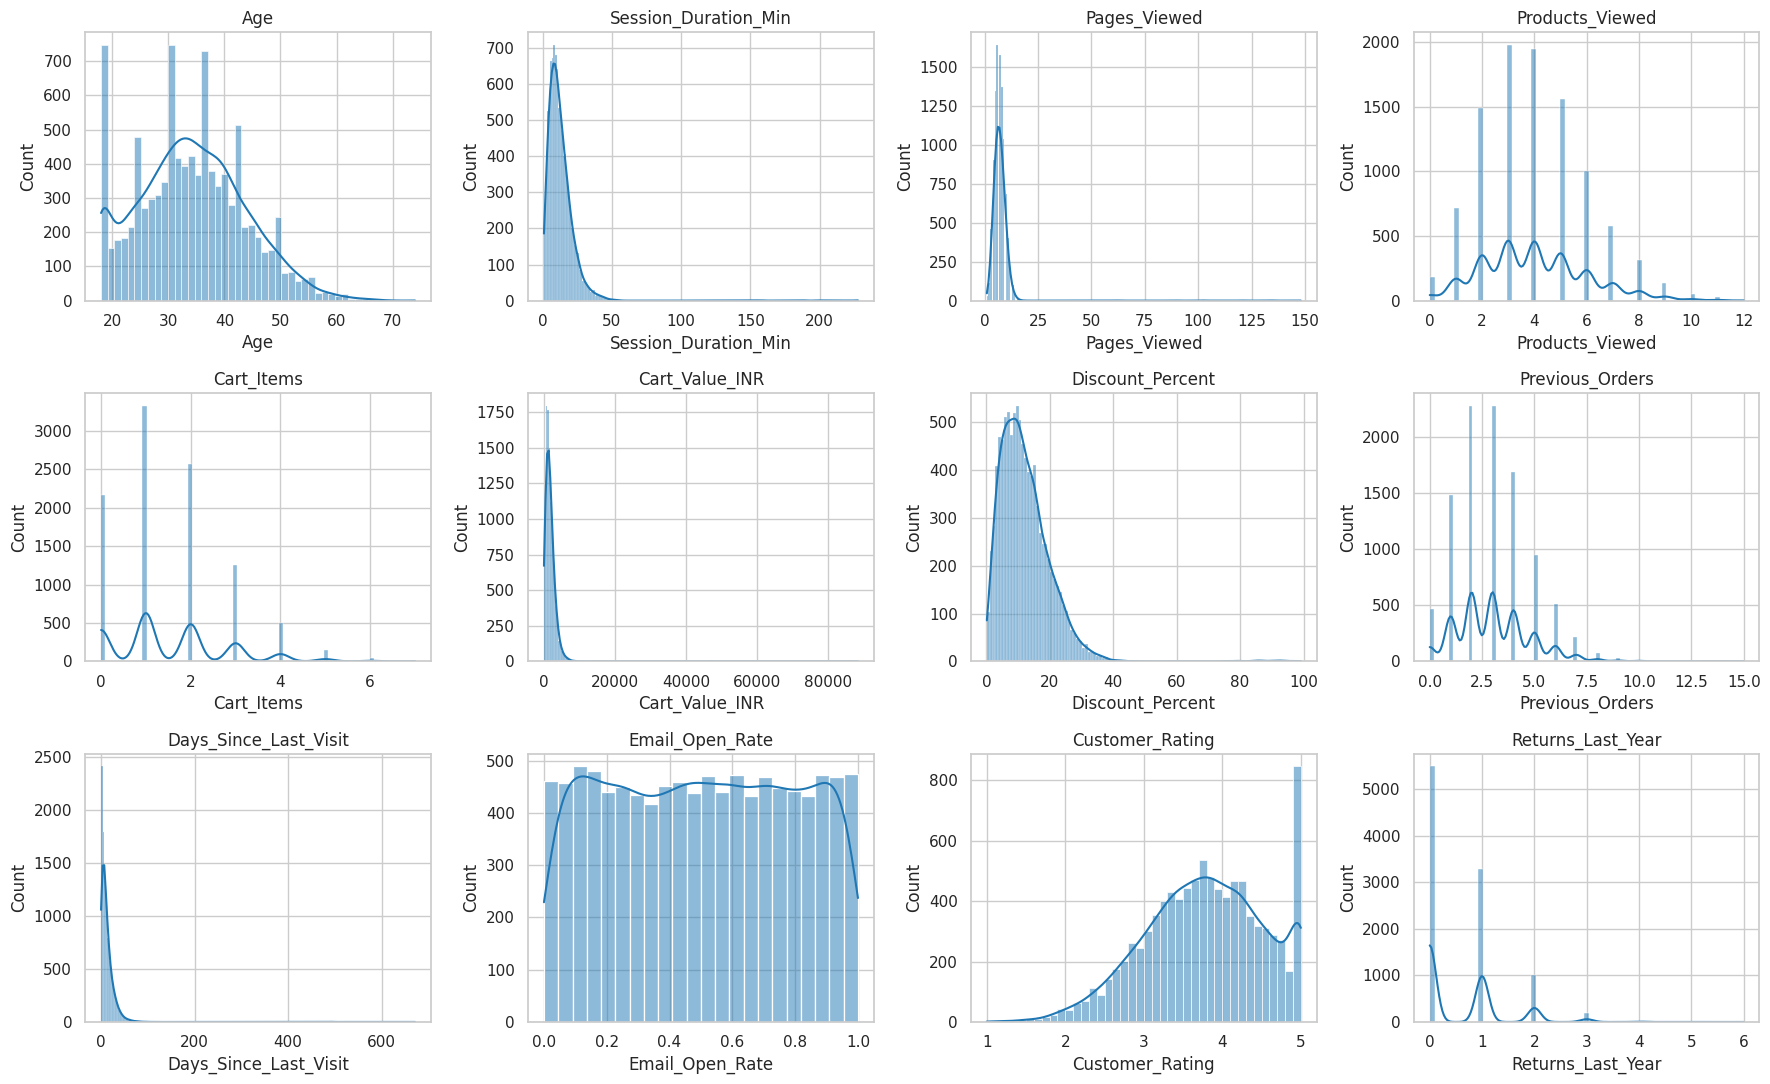

In [55]:
fig, ax = plt.subplots(3, 4, figsize=(18, 11))
for a, c in zip(ax.ravel(), num_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=a, color="tab:blue"); a.set_title(c)
plt.tight_layout(); plt.show()

### 4.3 Numeric features vs Purchase

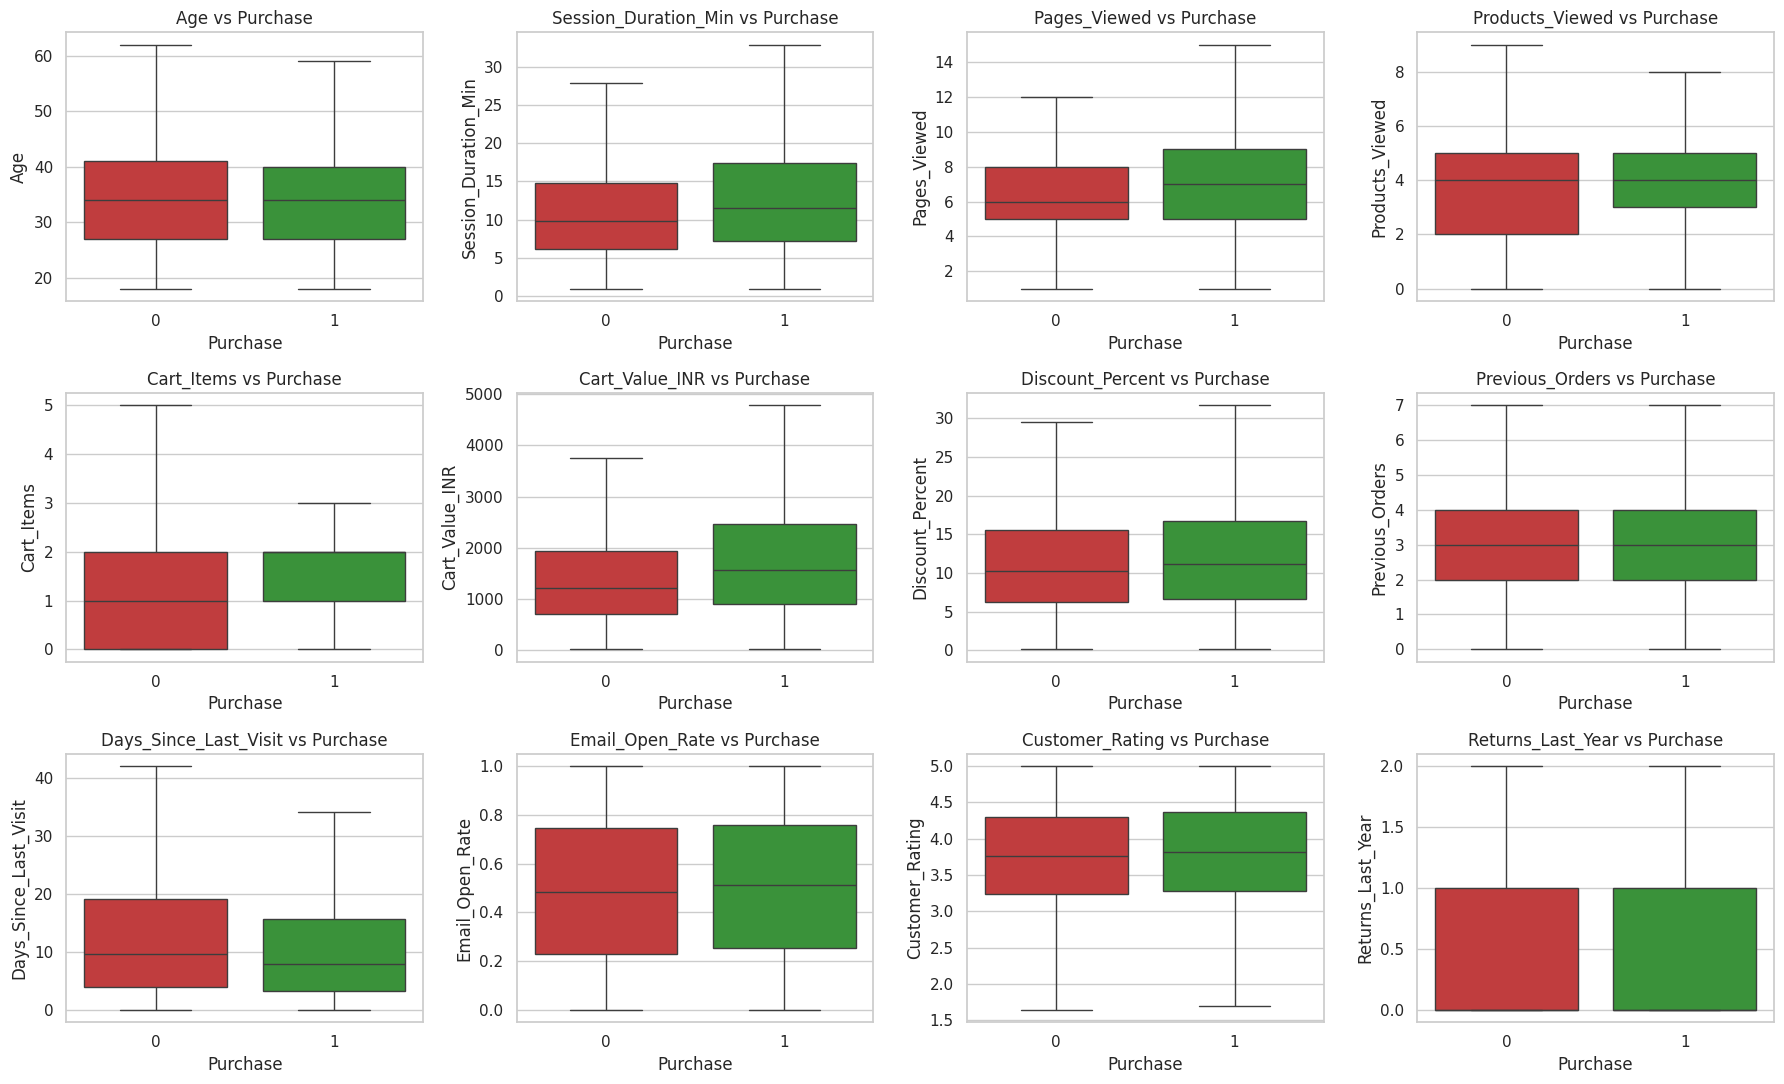

Purchase,median (No),median (Yes)
Age,34.00,34.00
Session_Duration_Min,9.88,11.53
Pages_Viewed,6.00,7.00
Products_Viewed,4.00,4.00
Cart_Items,1.00,2.00
Cart_Value_INR,1205.47,1567.17
Discount_Percent,10.32,11.12
Previous_Orders,3.00,3.00
Days_Since_Last_Visit,9.58,7.94
Email_Open_Rate,0.48,0.51


In [56]:
fig, ax = plt.subplots(3, 4, figsize=(18, 11))
for a, c in zip(ax.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=c, ax=a, showfliers=False, palette=["tab:red", "tab:green"]); a.set_title(f"{c} vs Purchase")
plt.tight_layout(); plt.show()
display(df.groupby(TARGET)[num_cols].median().T.rename(columns={0: "median (No)", 1: "median (Yes)"}).round(2))

### 4.4 Categorical features vs Purchase rate

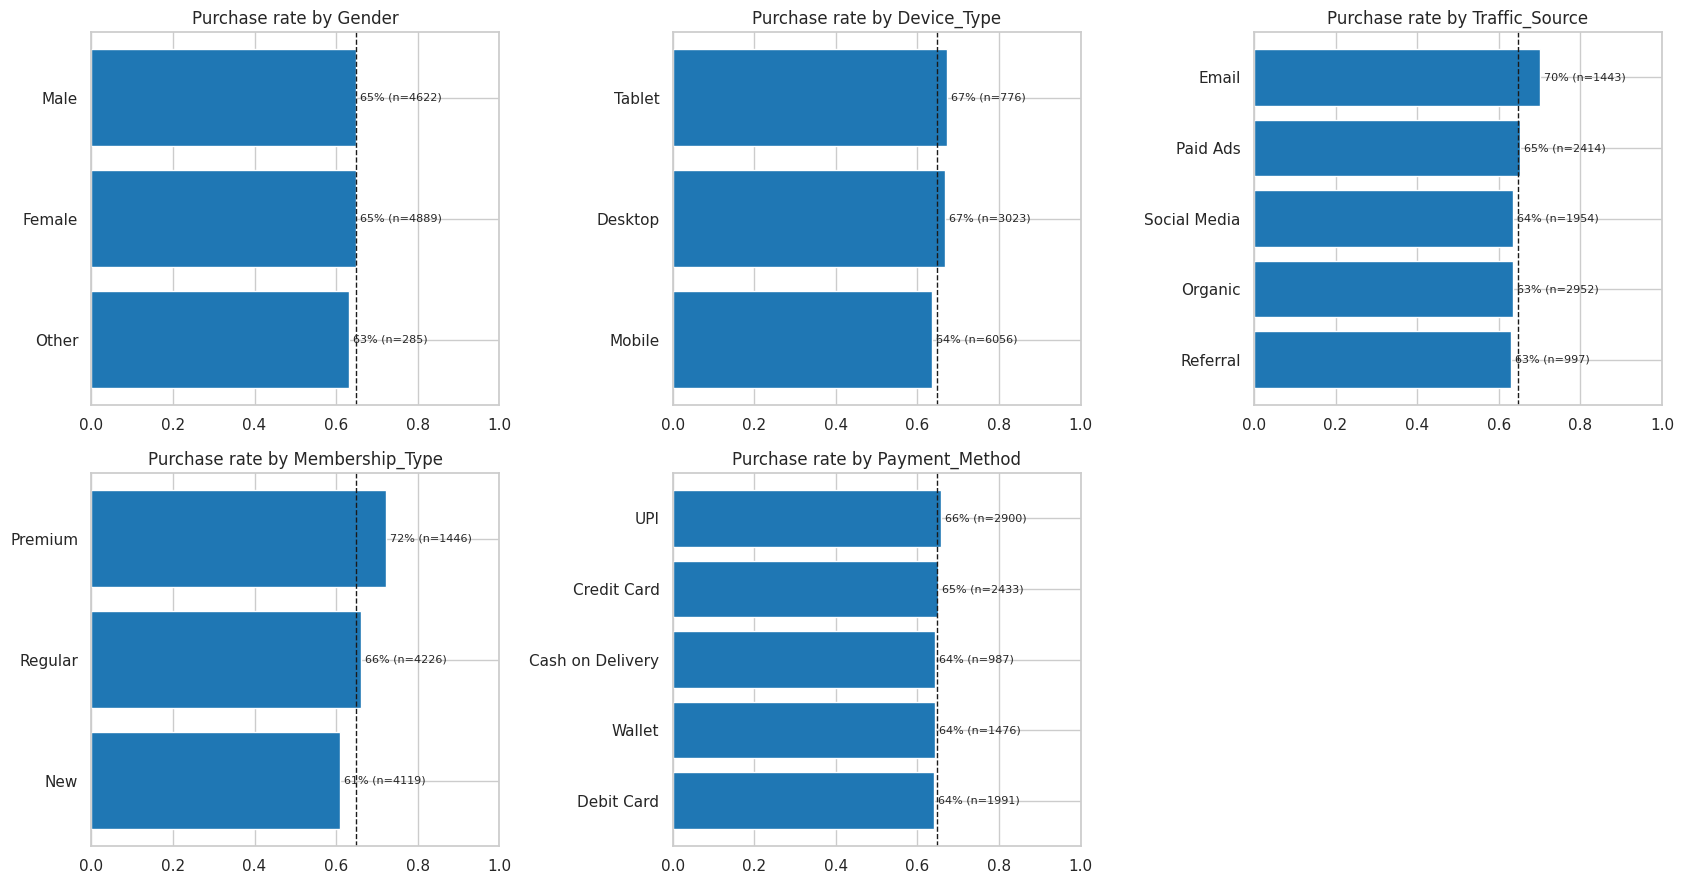

In [57]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for a, c in zip(ax.ravel(), cat_cols):
    r = df.groupby(c)[TARGET].agg(["mean", "count"]).sort_values("mean")
    a.barh(r.index, r["mean"], color="tab:blue"); a.axvline(df[TARGET].mean(), color="k", ls="--", lw=1)
    a.set_title(f"Purchase rate by {c}"); a.set_xlim(0, 1)
    for i, (m, n) in enumerate(zip(r["mean"], r["count"])): a.text(m + .01, i, f"{m:.0%} (n={n})", va="center", fontsize=8)
ax.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

### 4.5 Correlation analysis

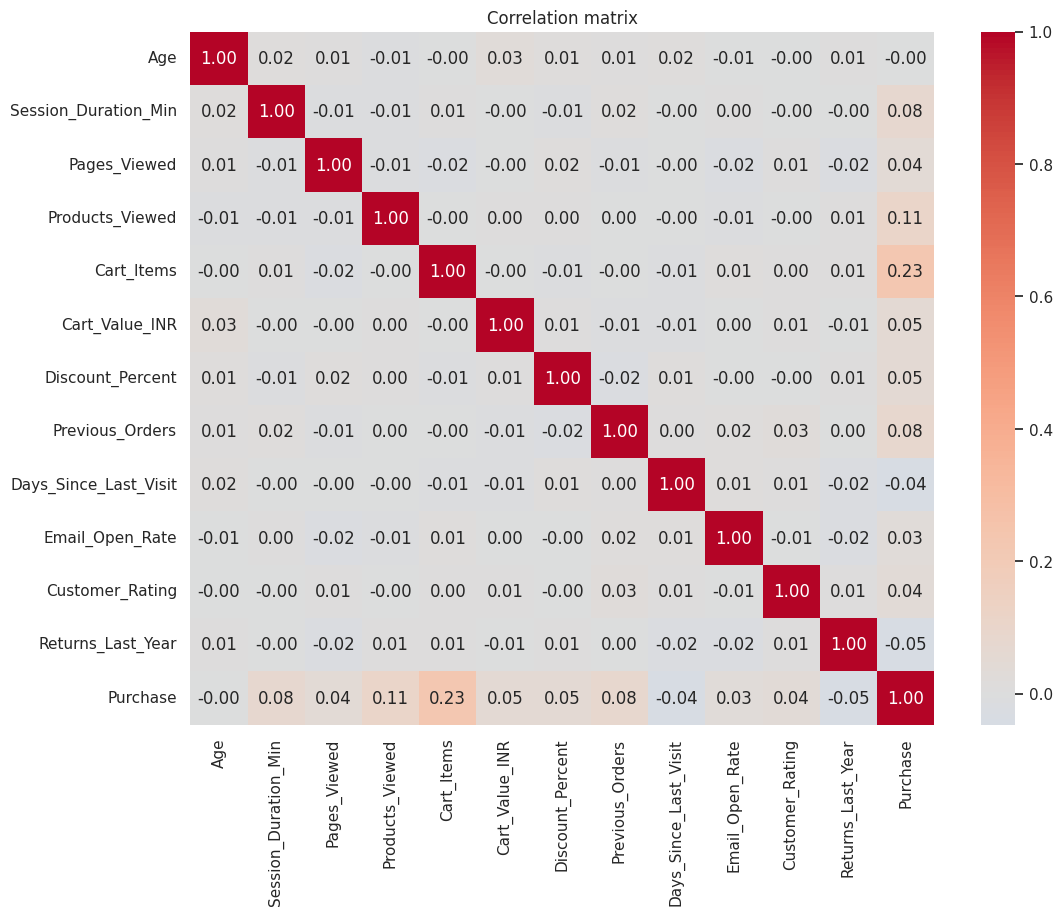

Cart_Items               0.232
Products_Viewed          0.109
Previous_Orders          0.082
Session_Duration_Min     0.079
Cart_Value_INR           0.054
Discount_Percent         0.050
Pages_Viewed             0.042
Customer_Rating          0.037
Email_Open_Rate          0.032
Age                     -0.001
Days_Since_Last_Visit   -0.043
Returns_Last_Year       -0.047
Name: Purchase, dtype: float64


In [58]:
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()
print(df[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

## 5. Outlier detection & handling

In [59]:
def iqr_bounds(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); i = q3 - q1; return q1 - 1.5*i, q3 + 1.5*i
rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c].dropna()); n = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append([c, round(lo, 2), round(hi, 2), round(float(df[c].min()), 2), round(float(df[c].max()), 2), n, round(n/len(df)*100, 2)])
out = pd.DataFrame(rows, columns=["feature", "lower_fence", "upper_fence", "min", "max", "n_outliers", "pct"])
display(out.sort_values("n_outliers", ascending=False))

,feature,lower_fence,upper_fence,min,max,n_outliers,pct
4,Cart_Items,-0.50,3.50,0.00,7.00,694,6.94
8,Days_Since_Last_Visit,-16.47,36.67,0.00,671.77,508,5.08
5,Cart_Value_INR,-1370.12,4470.02,14.93,88342.76,346,3.46
1,Session_Duration_Min,-8.01,31.44,1.00,227.76,325,3.25
11,Returns_Last_Year,-1.50,2.50,0.00,6.00,228,2.28
3,Products_Viewed,0.00,8.00,0.00,12.00,216,2.16
6,Discount_Percent,-8.20,30.88,0.14,99.15,176,1.76
7,Previous_Orders,-1.00,7.00,0.00,15.00,119,1.19
0,Age,7.50,59.50,18.00,74.00,58,0.58
2,Pages_Viewed,-1.00,15.00,1.00,148.08,45,0.45


In [60]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


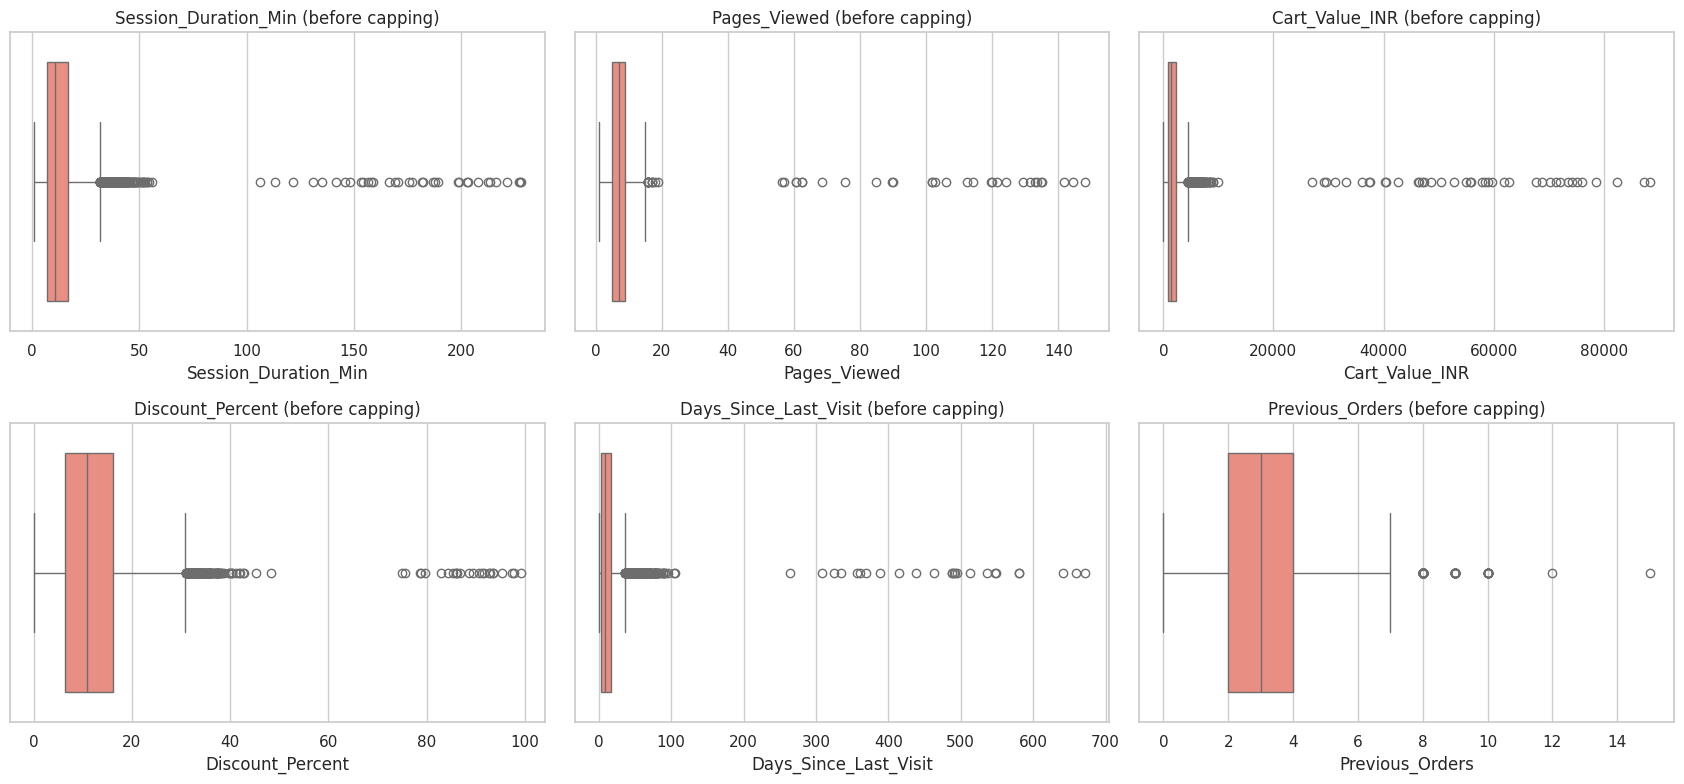

In [61]:
heavy = ["Session_Duration_Min", "Pages_Viewed", "Cart_Value_INR", "Discount_Percent", "Days_Since_Last_Visit", "Previous_Orders"]
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(ax.ravel(), heavy): sns.boxplot(x=df[c], ax=a, color="salmon"); a.set_title(f"{c} (before capping)")
plt.tight_layout(); plt.show()

**Treatment decision:** outliers are genuine-looking extremes (e.g. a 670-day gap since last visit, a 99% discount, 148 pages in a session). Deleting them would lose rows and logistic regression is sensitive to extreme values, so we **cap (winsorize) at the IQR fences**: values beyond `Q1 - 1.5*IQR` / `Q3 + 1.5*IQR` are clipped to the fence. Fences are learned on training data only (Section 8).

**Which columns are capped?** Only the **continuous** features (Age, Session_Duration_Min, Pages_Viewed, Cart_Value_INR, Discount_Percent, Days_Since_Last_Visit). Discrete counts such as `Cart_Items`, `Products_Viewed`, `Previous_Orders`, `Returns_Last_Year` are *valid* values, not errors: purchase rate rises steadily with cart items (50% at 0 items -> 84% at 4 -> ~93% at 5+), so capping them at the IQR fence would erase real signal. `Email_Open_Rate` and `Customer_Rating` are bounded by definition and have no real outliers.

Missing after imputation: 0


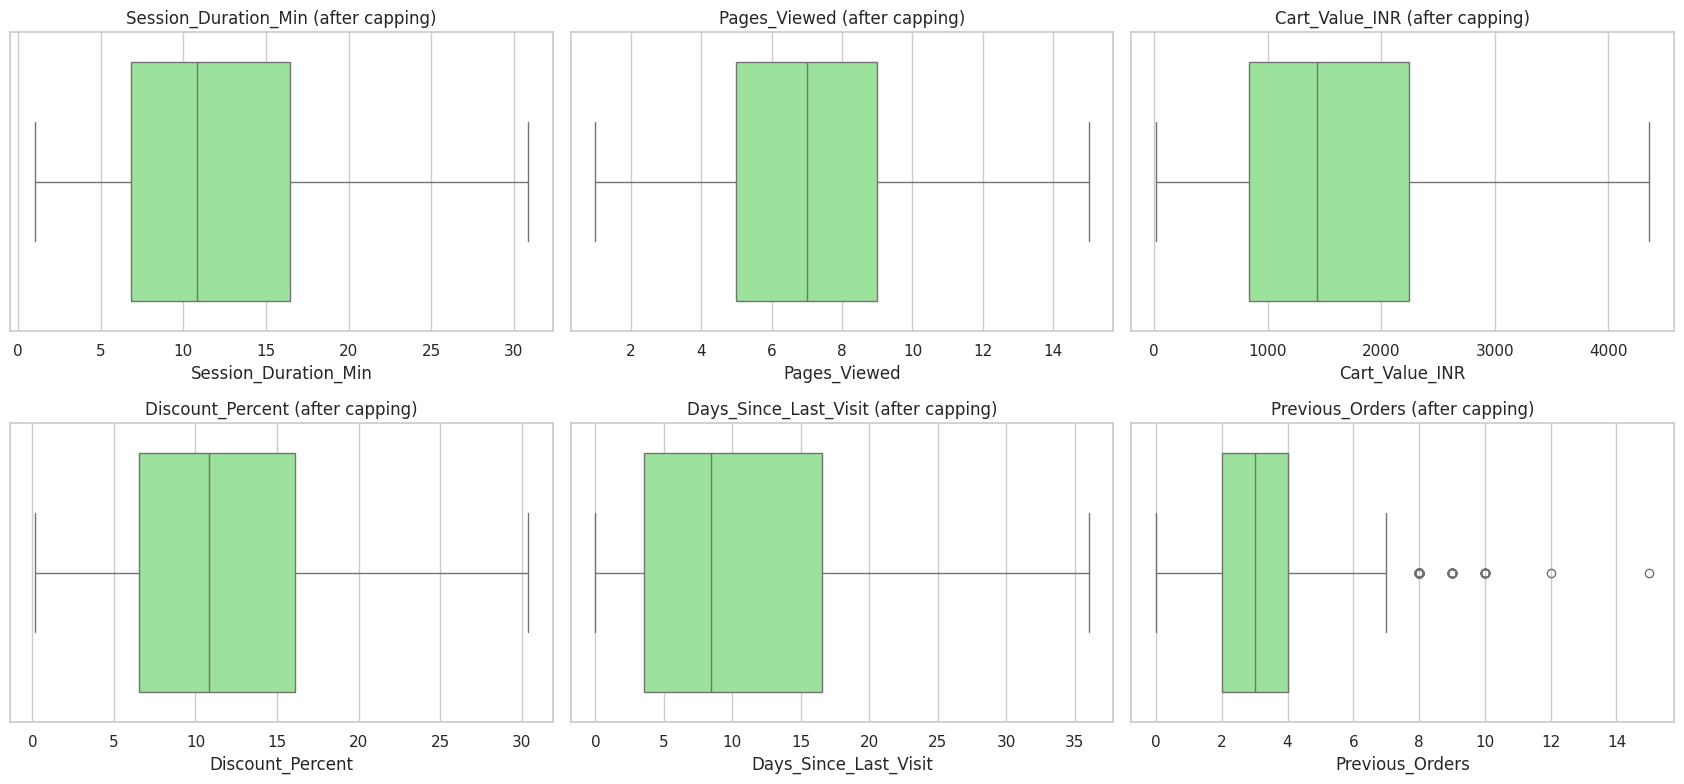

,max before,max after
Session_Duration_Min,227.76,30.86
Pages_Viewed,148.08,15.00
Cart_Value_INR,88342.76,4360.58
Discount_Percent,99.15,30.39
Days_Since_Last_Visit,671.77,36.00
Previous_Orders,15.00,15.00


In [62]:
# Demonstration of before / after on the full dataset (EDA only; model uses the leakage-safe pipeline)
demo = df.copy()
for c in num_cols:
    demo[c] = demo[c].fillna(demo[c].median())
    if c in cap_cols: lo, hi = iqr_bounds(demo[c]); demo[c] = demo[c].clip(lo, hi)
for c in cat_cols: demo[c] = demo[c].fillna(demo[c].mode()[0])
print("Missing after imputation:", demo.isna().sum().sum())
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(ax.ravel(), heavy): sns.boxplot(x=demo[c], ax=a, color="lightgreen"); a.set_title(f"{c} (after capping)")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"max before": df[heavy].max(), "max after": demo[heavy].max()}).round(2))

## 6. Categorical encoding & feature scaling

- **Encoding:** nominal categories (Gender, Device_Type, Traffic_Source, Membership_Type, Payment_Method) have no order, so we use **One-Hot Encoding** with `drop='first'` (avoids the dummy-variable trap / multicollinearity). Unknown categories at prediction time are ignored safely.
- **Scaling:** **StandardScaler** (mean 0, std 1). Logistic regression is optimised by gradient-based methods and its coefficients are only comparable when features share a scale.

In [63]:
enc = pd.get_dummies(demo, columns=cat_cols, drop_first=True, dtype=int)
sc = enc.copy(); sc[num_cols] = StandardScaler().fit_transform(sc[num_cols])
print("Shape after encoding:", enc.shape)
display(sc.head())
display(sc[num_cols].describe().loc[["mean", "std"]].round(3))

Shape after encoding: (10000, 27)


,Age,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,...,Traffic_Source_Organic,Traffic_Source_Paid Ads,Traffic_Source_Referral,Traffic_Source_Social Media,Membership_Type_Premium,Membership_Type_Regular,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_UPI,Payment_Method_Wallet
0,0.308871,-0.767077,-0.816785,2.004996,-1.240274,2.528205,0.301853,-0.578146,-0.834255,-0.781233,...,0,0,1,0,0,1,1,0,0,0
1,-1.078020,0.059776,0.813036,0.504587,-0.425912,1.296347,-0.668895,-0.578146,2.426444,-1.565125,...,1,0,0,0,1,0,0,1,0,0
2,0.842291,-0.087434,0.813036,0.504587,-0.425912,-0.207820,-0.311855,0.580696,-0.761938,1.016905,...,0,0,1,0,0,1,0,0,0,1
3,0.948975,-0.231892,-0.001874,1.004724,1.202814,1.047617,-0.740590,-1.736988,-0.225010,-0.255200,...,0,0,1,0,1,0,0,0,1,0
4,-1.718124,-0.040657,-1.224240,-0.495685,2.017177,1.895517,0.634517,0.580696,-0.698537,-0.526812,...,0,0,0,1,0,1,0,1,0,0


,Age,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year
mean,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 7. Train / test split

In [64]:
X, y = df.drop(columns=TARGET), df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_tr.shape, "| Test:", X_te.shape)
print("Purchase rate - train:", round(y_tr.mean(), 4), "| test:", round(y_te.mean(), 4))

Train: (8000, 17) | Test: (2000, 17)
Purchase rate - train: 0.648 | test: 0.648


Split is **80/20, stratified** so both sets keep the same purchase rate. It happens **before** any fitting, so the test set stays truly unseen.

## 8. Build the Logistic Regression model (full preprocessing pipeline)

In [65]:
class IQRCapper(BaseEstimator, TransformerMixin):
    """Cap outliers at Q1-1.5*IQR / Q3+1.5*IQR (fences learned on train only)."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X); q1, q3 = X.quantile(.25), X.quantile(.75); i = q3 - q1
        self.lo_, self.hi_ = (q1 - 1.5*i).values, (q3 + 1.5*i).values; return self
    def transform(self, X): return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, names=None): return np.asarray(names)

cap_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("cap", IQRCapper()), ("scale", StandardScaler())])
cnt_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore"))])
prep = ColumnTransformer([("cap", cap_pipe, cap_cols), ("cnt", cnt_pipe, count_cols), ("cat", cat_pipe, cat_cols)])

model = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000, random_state=42))])
model.fit(X_tr, y_tr)

cv = StratifiedKFold(5, shuffle=True, random_state=42)
for m in ["accuracy", "f1", "roc_auc"]:
    s = cross_val_score(model, X_tr, y_tr, cv=cv, scoring=m); print(f"5-fold CV {m:9s}: {s.mean():.4f} +/- {s.std():.4f}")

5-fold CV accuracy : 0.6983 +/- 0.0070
5-fold CV f1       : 0.7868 +/- 0.0054
5-fold CV roc_auc  : 0.7281 +/- 0.0071


## 9. Model evaluation

===== Logistic Regression (baseline) (threshold = 0.5) =====
Accuracy  : 0.7045
Precision : 0.7279
Recall    : 0.8688
F1        : 0.7921
ROC_AUC   : 0.7411

              precision    recall  f1-score   support

 No Purchase       0.62      0.40      0.49       704
    Purchase       0.73      0.87      0.79      1296

    accuracy                           0.70      2000
   macro avg       0.68      0.64      0.64      2000
weighted avg       0.69      0.70      0.69      2000

TN=283  FP=421  FN=170  TP=1126


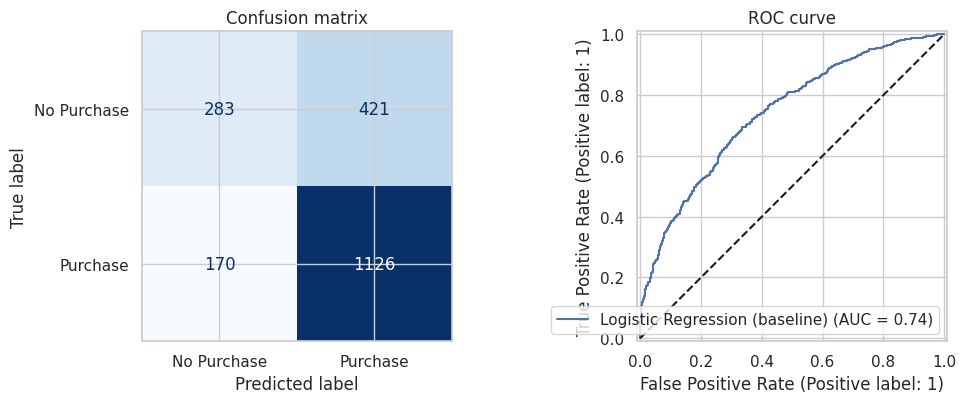

In [66]:
def metrics(m, X, y, thr=0.5):
    p = m.predict_proba(X)[:, 1]; pr = (p >= thr).astype(int)
    return dict(Accuracy=accuracy_score(y, pr), Precision=precision_score(y, pr), Recall=recall_score(y, pr),
                F1=f1_score(y, pr), ROC_AUC=roc_auc_score(y, p))

def evaluate(m, name, thr=0.5):
    p = m.predict_proba(X_te)[:, 1]; pr = (p >= thr).astype(int)
    r = metrics(m, X_te, y_te, thr)
    print(f"===== {name} (threshold = {thr}) =====")
    for k, v in r.items(): print(f"{k:10s}: {v:.4f}")
    print(); print(classification_report(y_te, pr, target_names=["No Purchase", "Purchase"]))
    cm = confusion_matrix(y_te, pr); tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ConfusionMatrixDisplay(cm, display_labels=["No Purchase", "Purchase"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
    ax[0].set_title("Confusion matrix")
    RocCurveDisplay.from_predictions(y_te, p, ax=ax[1], name=name); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curve")
    plt.tight_layout(); plt.show(); return r

res_base = evaluate(model, "Logistic Regression (baseline)")

In [67]:
# Overfitting check: train vs test
print(pd.DataFrame({"Train": metrics(model, X_tr, y_tr), "Test": metrics(model, X_te, y_te)}).round(4))

            Train    Test
Accuracy   0.7008  0.7045
Precision  0.7265  0.7279
Recall     0.8630  0.8688
F1         0.7889  0.7921
ROC_AUC    0.7320  0.7411


### 9.1 Improving minority-class detection
Only ~35% of sessions are non-purchases, so the baseline favours the majority class (high recall for *Purchase*, weak recall for *No Purchase*). Two standard remedies, both still Logistic Regression:
1. `class_weight="balanced"`
2. A tuned decision threshold

===== Logistic Regression (class_weight=balanced) (threshold = 0.5) =====
Accuracy  : 0.6715
Precision : 0.7978
Recall    : 0.6605
F1        : 0.7227
ROC_AUC   : 0.7408

              precision    recall  f1-score   support

 No Purchase       0.53      0.69      0.60       704
    Purchase       0.80      0.66      0.72      1296

    accuracy                           0.67      2000
   macro avg       0.66      0.68      0.66      2000
weighted avg       0.70      0.67      0.68      2000

TN=487  FP=217  FN=440  TP=856


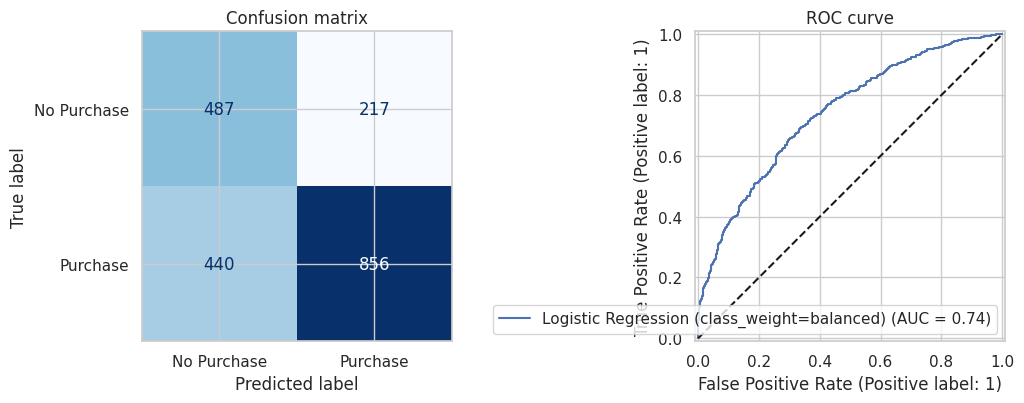

In [68]:
model_bal = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))])
model_bal.fit(X_tr, y_tr)
res_bal = evaluate(model_bal, "Logistic Regression (class_weight=balanced)")

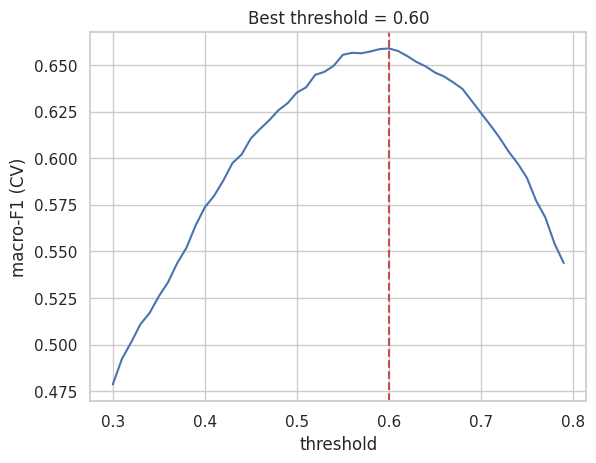

===== Logistic Regression (tuned threshold) (threshold = 0.6000000000000003) =====
Accuracy  : 0.6905
Precision : 0.7750
Recall    : 0.7361
F1        : 0.7550
ROC_AUC   : 0.7411

              precision    recall  f1-score   support

 No Purchase       0.56      0.61      0.58       704
    Purchase       0.77      0.74      0.76      1296

    accuracy                           0.69      2000
   macro avg       0.67      0.67      0.67      2000
weighted avg       0.70      0.69      0.69      2000

TN=427  FP=277  FN=342  TP=954


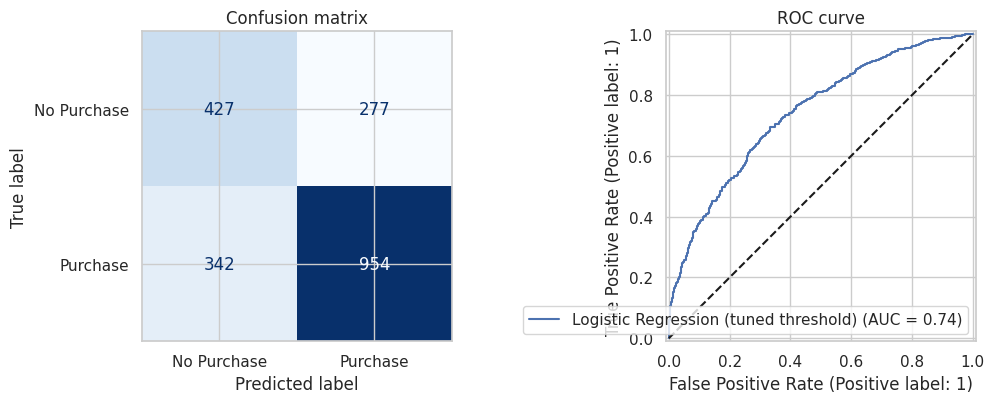

In [69]:
# Threshold tuning chosen on TRAIN cross-validated probabilities (no test leakage)
from sklearn.model_selection import cross_val_predict
p_cv = cross_val_predict(model, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
ths = np.arange(0.30, 0.80, 0.01)
f1m = [f1_score(y_tr, p_cv >= t, average="macro") for t in ths]
best_t = ths[int(np.argmax(f1m))]
plt.plot(ths, f1m); plt.axvline(best_t, color="r", ls="--"); plt.xlabel("threshold"); plt.ylabel("macro-F1 (CV)")
plt.title(f"Best threshold = {best_t:.2f}"); plt.show()
res_thr = evaluate(model, f"Logistic Regression (tuned threshold)", thr=best_t)

,Accuracy,Precision,Recall,F1,ROC_AUC
Baseline (0.5),0.7045,0.7279,0.8688,0.7921,0.7411
Balanced weights,0.6715,0.7978,0.6605,0.7227,0.7408
Tuned thr (0.60),0.6905,0.7750,0.7361,0.7550,0.7411


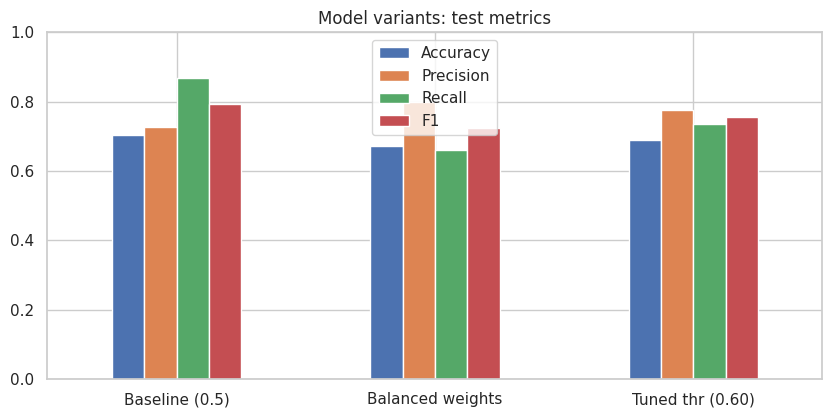

In [70]:
cmp = pd.DataFrame({"Baseline (0.5)": res_base, "Balanced weights": res_bal, f"Tuned thr ({best_t:.2f})": res_thr}).T
display(cmp.round(4))
cmp.drop(columns="ROC_AUC").plot.bar(figsize=(10, 4.5), rot=0, title="Model variants: test metrics"); plt.ylim(0, 1); plt.show()

## 10. Feature importance & business interpretation

,coefficient,odds_ratio
Cart_Items,0.607,1.836
Membership_Type_Premium,0.539,1.715
Cart_Value_INR,0.408,1.504
Session_Duration_Min,0.273,1.314
Pages_Viewed,0.262,1.300
Products_Viewed,0.259,1.295
Membership_Type_Regular,0.241,1.273
Previous_Orders,0.219,1.245
Discount_Percent,0.148,1.160
Customer_Rating,0.088,1.092


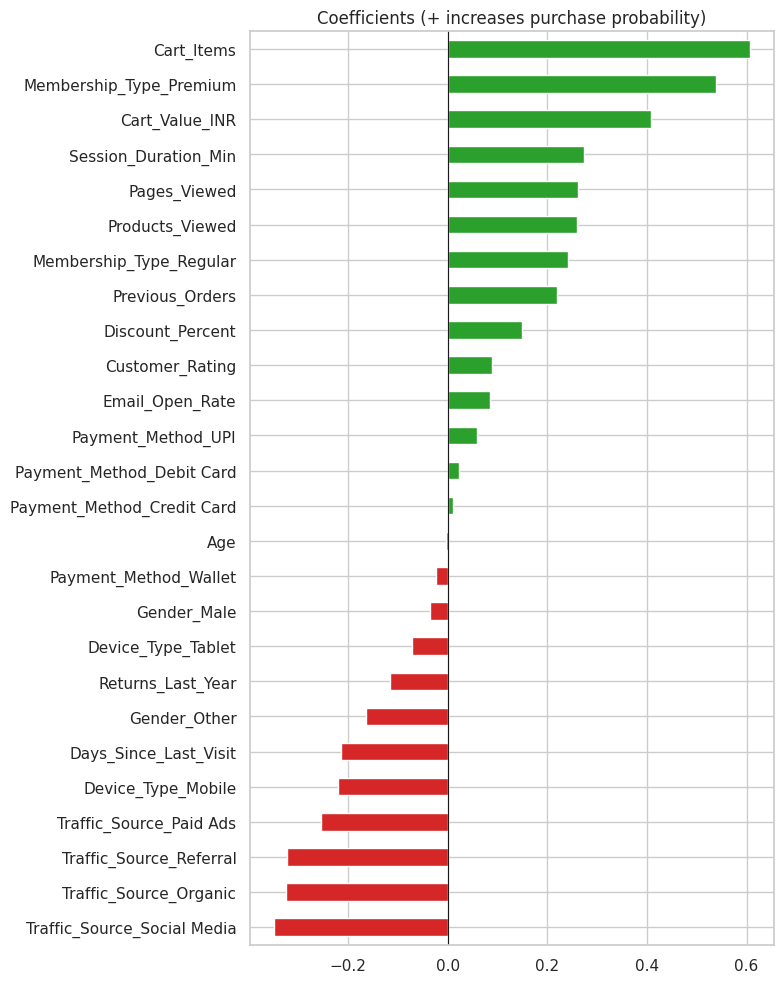

In [71]:
names = model.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
coef = pd.Series(model.named_steps["clf"].coef_[0], index=names)
tbl = pd.DataFrame({"coefficient": coef, "odds_ratio": np.exp(coef)}).sort_values("coefficient", ascending=False)
display(tbl.round(3))
tbl["coefficient"].sort_values().plot.barh(figsize=(8, 10), color=np.where(tbl["coefficient"].sort_values() > 0, "tab:green", "tab:red"))
plt.title("Coefficients (+ increases purchase probability)"); plt.axvline(0, color="k", lw=.8); plt.tight_layout(); plt.show()

**How to read it:** numeric features are standardised, so `odds_ratio` = change in odds of purchase for a **1 standard-deviation increase** in that feature. For one-hot columns it is the odds versus the dropped reference category (alphabetically first: Female, Desktop, Email, New, Credit Card).

## 11. Predict purchase decisions for new customers

In [72]:
new_customers = pd.DataFrame([
 {"Age": 29, "Gender": "Female", "Device_Type": "Mobile", "Traffic_Source": "Email", "Membership_Type": "Premium",
  "Payment_Method": "UPI", "Session_Duration_Min": 14.5, "Pages_Viewed": 10, "Products_Viewed": 6, "Cart_Items": 3,
  "Cart_Value_INR": 4200, "Discount_Percent": 12, "Previous_Orders": 6, "Days_Since_Last_Visit": 2,
  "Email_Open_Rate": 0.8, "Customer_Rating": 4.5, "Returns_Last_Year": 0},
 {"Age": 45, "Gender": "Male", "Device_Type": "Desktop", "Traffic_Source": "Paid Ads", "Membership_Type": "New",
  "Payment_Method": "Credit Card", "Session_Duration_Min": 2.0, "Pages_Viewed": 2, "Products_Viewed": 1, "Cart_Items": 0,
  "Cart_Value_INR": 0, "Discount_Percent": 3, "Previous_Orders": 0, "Days_Since_Last_Visit": 60,
  "Email_Open_Rate": 0.1, "Customer_Rating": 3.0, "Returns_Last_Year": 2},
 {"Age": 34, "Gender": "Other", "Device_Type": "Tablet", "Traffic_Source": "Social Media", "Membership_Type": "Regular",
  "Payment_Method": "Wallet", "Session_Duration_Min": 8.0, "Pages_Viewed": 6, "Products_Viewed": 4, "Cart_Items": 1,
  "Cart_Value_INR": 1400, "Discount_Percent": 10, "Previous_Orders": 3, "Days_Since_Last_Visit": 8,
  "Email_Open_Rate": 0.5, "Customer_Rating": 3.8, "Returns_Last_Year": 1},
])
proba = model.predict_proba(new_customers)[:, 1]
out = new_customers[["Age", "Membership_Type", "Traffic_Source", "Cart_Items", "Cart_Value_INR", "Session_Duration_Min"]].copy()
out["P(Purchase)"] = (proba*100).round(1).astype(str) + "%"
out["Prediction"] = np.where(proba >= 0.5, "Purchase", "No Purchase")
display(out)

,Age,Membership_Type,Traffic_Source,Cart_Items,Cart_Value_INR,Session_Duration_Min,P(Purchase),Prediction
0,29,Premium,Email,3,4200,14.5,98.9%,Purchase
1,45,New,Paid Ads,0,0,2.0,2.9%,No Purchase
2,34,Regular,Social Media,1,1400,8.0,48.6%,No Purchase


In [73]:
joblib.dump(model, "purchase_model.pkl")   # reusable: joblib.load("purchase_model.pkl").predict(new_df)
print("Model saved -> purchase_model.pkl")

Model saved -> purchase_model.pkl


## 12. Conclusion & business recommendations

### Summary of work (maps to the 4 project objectives)
| Objective | Done |
|---|---|
| 1. Understand data + EDA | 10,000 records, 18 columns; target 64.8% Purchase / 35.2% No Purchase; distributions, target-wise comparisons, correlations |
| 2. Preprocessing | 11 columns with missing values (~1.5-3.3% each) imputed; IQR capping of 6 continuous features; one-hot encoding (5 categoricals); standard scaling; all fitted on train only |
| 3. Model | Logistic Regression in a single leakage-safe sklearn `Pipeline`; stratified 80/20 split; 5-fold CV |
| 4. Evaluation + prediction | Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC reported; 3 new customers scored; model saved to `purchase_model.pkl` |

### Model performance (test set, 2,000 customers)
| Variant | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline (threshold 0.50) | 0.705 | 0.728 | 0.869 | 0.792 | 0.741 |
| `class_weight="balanced"` | 0.672 | 0.798 | 0.661 | 0.723 | 0.741 |
| Tuned threshold (0.60) | 0.691 | 0.775 | 0.736 | 0.755 | 0.741 |

- **No overfitting:** train and test scores are almost identical, and CV ROC-AUC (0.728 +/- 0.007) matches the test AUC (0.741).
- **ROC-AUC 0.74** means the model ranks a random buyer above a random non-buyer about 74% of the time: a useful, moderate signal. It is not highly accurate, which is expected: browsing data does not fully capture purchase intent, and a linear model is limited to additive effects.
- **Baseline** catches 87% of real buyers but only ~40% of non-buyers (it leans toward predicting "Purchase"). **Balanced weights** reverse this: non-buyer recall rises to ~69%, at the cost of missing more buyers. Which variant to use is a business choice: use the **baseline** to capture as many likely buyers as possible, and the **balanced / tuned** version when wasting a promotion on a non-buyer is costly or you need to find at-risk visitors.

### What drives purchases (coefficients / odds ratios, 1 std-dev increase)
- **Cart_Items (OR 1.84)** is the strongest driver; purchase rate climbs from 50% with an empty cart to ~84% at 4 items and ~93% at 5+.
- **Premium members (OR 1.72 vs New)** and Regular members (1.27) are more likely to buy than New customers (conversion: Premium 72%, Regular 66%, New 61%).
- Higher **Cart_Value (1.50)**, **Session_Duration (1.31)**, **Pages_Viewed (1.30)**, **Products_Viewed (1.30)** and **Previous_Orders (1.25)** all raise purchase odds.
- **Negative:** longer **Days_Since_Last_Visit (0.81)** and more **Returns_Last_Year (0.89)** lower the odds.
- **Traffic source:** Email converts best (70%); Paid Ads, Referral, Organic and Social Media are all lower (63-65%). **Mobile** users convert slightly less than Desktop/Tablet.
- Age, Gender and Payment Method have essentially no effect.

### Recommendations for ShopSmart marketing
1. **Prioritise email campaigns**; email traffic is the highest-converting channel.
2. **Retarget visitors with filled carts** (3+ items) with a nudge or small incentive; they are the most likely to convert, and those with 1-2 items are the best group to push over the line.
3. **Grow Premium membership** and offer a loyalty path to New customers: membership tier is the strongest customer-level signal.
4. **Re-engage lapsed visitors** (long gap since last visit) before they churn.
5. **Improve mobile checkout**; mobile has the lowest conversion despite being 60% of sessions.
6. **Reduce returns** (e.g. better product information) as returns are associated with lower purchase likelihood.
7. Use `purchase_model.pkl` to score live sessions and trigger interventions for visitors in the uncertain 40-60% probability band.

### Limitations & next steps
- Moderate AUC: try Random Forest / Gradient Boosting, interaction terms, or more behavioural features (e.g. time on cart page) to improve it.
- Coefficients show **association, not causation**; validate recommendations with A/B tests.
- Scores for extreme profiles (e.g. 2.9% for an empty-cart, short-session visitor) should be read as "very unlikely", not as precise probabilities.